# data understanding

looking at the data files before doing any forecasting.


In [1]:
import os
import duckdb
import pandas as pd
import matplotlib.pyplot as plt


### checking file sizes

my laptop has 8gb ram so reading transactions directly with pandas will crash it. articles is small enough to load normally.


In [2]:
print("articles.csv:", round(os.path.getsize("data/raw/articles.csv") / (1024 * 1024), 1), "mb")
print("transactions_train.csv:", round(os.path.getsize("data/raw/transactions_train.csv") / (1024 * 1024), 1), "mb")


articles.csv: 34.5 mb
transactions_train.csv: 3326.4 mb


### looking at articles

let's load articles.csv into pandas.


In [3]:
articles = pd.read_csv("data/raw/articles.csv")

print("shape:", articles.shape)
articles.head()


shape: (105542, 25)


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,...,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


### missing values

let's see if any columns have missing values.


In [4]:
articles.isnull().sum()


article_id                        0
product_code                      0
prod_name                         0
product_type_no                   0
product_type_name                 0
product_group_name                0
graphical_appearance_no           0
graphical_appearance_name         0
colour_group_code                 0
colour_group_name                 0
perceived_colour_value_id         0
perceived_colour_value_name       0
perceived_colour_master_id        0
perceived_colour_master_name      0
department_no                     0
department_name                   0
index_code                        0
index_name                        0
index_group_no                    0
index_group_name                  0
section_no                        0
section_name                      0
garment_group_no                  0
garment_group_name                0
detail_desc                     416
dtype: int64

only detail_desc has missing values. all category columns are complete.


### product categories

let's see what product groups exist and how many items each has in the catalog.


In [5]:
cat_counts = articles["product_group_name"].value_counts()
cat_counts


product_group_name
Garment Upper body       42741
Garment Lower body       19812
Garment Full body        13292
Accessories              11158
Underwear                 5490
Shoes                     5283
Swimwear                  3127
Socks & Tights            2442
Nightwear                 1899
Unknown                    121
Underwear/nightwear         54
Cosmetic                    49
Bags                        25
Items                       17
Furniture                   13
Garment and Shoe care        9
Stationery                   5
Interior textile             3
Fun                          2
Name: count, dtype: int64

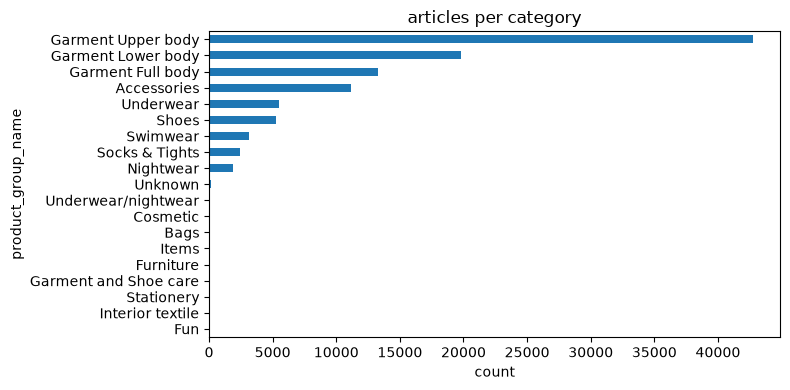

In [6]:
cat_counts.plot(kind="barh", figsize=(8, 4))
plt.title("articles per category")
plt.xlabel("count")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


### checking transactions with duckdb

transactions_train.csv is 3.5 gb so we use duckdb to query it without loading it all into ram.


In [7]:
con = duckdb.connect()

summary = con.execute("""
    SELECT 
        COUNT(*) as total_rows,
        MIN(t_dat) as start_date,
        MAX(t_dat) as end_date,
        COUNT(DISTINCT t_dat) as num_days
    FROM read_csv_auto('data/raw/transactions_train.csv')
""").df()

summary


,total_rows,start_date,end_date,num_days
0,31788324,2018-09-20,2020-09-22,734


31.78m transactions across 734 continuous days with no missing dates.


### checking actual sales by category

let's join transactions with articles to see what people actually bought.


In [8]:
sales = con.execute("""
    SELECT product_group_name as category, COUNT(*) as units_sold
    FROM read_csv_auto('data/raw/transactions_train.csv')
    JOIN read_csv_auto('data/raw/articles.csv')
    USING (article_id)
    GROUP BY product_group_name
    ORDER BY units_sold DESC
""").df()

sales["sales_pct"] = (sales["units_sold"] / sales["units_sold"].sum()) * 100
sales


,category,units_sold,sales_pct
0,Garment Upper body,12552755,39.488571
1,Garment Lower body,7046054,22.165541
2,Garment Full body,3552470,11.175393
3,Swimwear,2579222,8.113740
4,Underwear,2565858,8.071700
5,Accessories,1599593,5.032014
6,Shoes,745521,2.345267
7,Socks & Tights,685712,2.157119
8,Nightwear,348180,1.095308
9,Unknown,97040,0.305269


swimwear is less than 3% of the catalog but ranks 4th in actual sales with 2.58m units.
the top 6 categories make up over 94% of all sales.


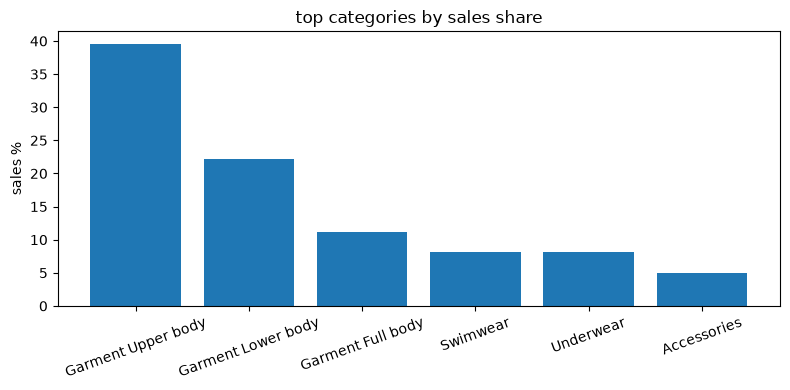

In [9]:
top = sales.head(6)

plt.figure(figsize=(8, 4))
plt.bar(top["category"], top["sales_pct"])
plt.xticks(rotation=20)
plt.ylabel("sales %")
plt.title("top categories by sales share")
plt.tight_layout()
plt.show()


### daily sales over time

checking total units sold per day across the 2 years.


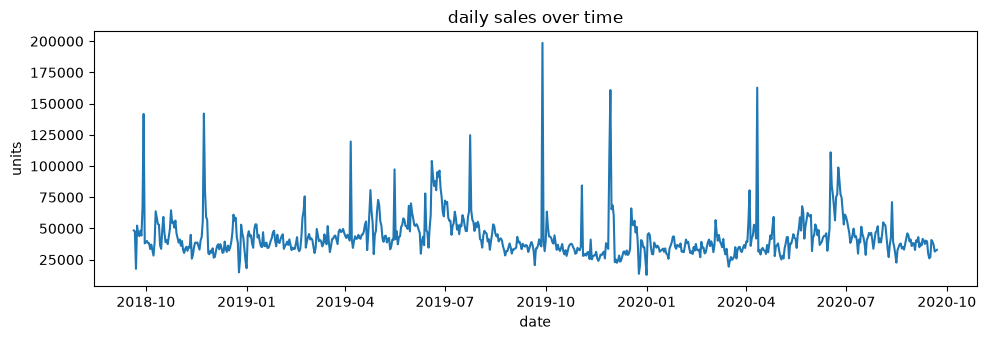

In [10]:
daily_sales = con.execute("""
    SELECT t_dat as date, COUNT(*) as units
    FROM read_csv_auto('data/raw/transactions_train.csv')
    GROUP BY t_dat
    ORDER BY date
""").df()

daily_sales["date"] = pd.to_datetime(daily_sales["date"])

plt.figure(figsize=(10, 3.5))
plt.plot(daily_sales["date"], daily_sales["units"])
plt.title("daily sales over time")
plt.xlabel("date")
plt.ylabel("units")
plt.tight_layout()
plt.show()


### day of week pattern

let's see which days have higher sales.


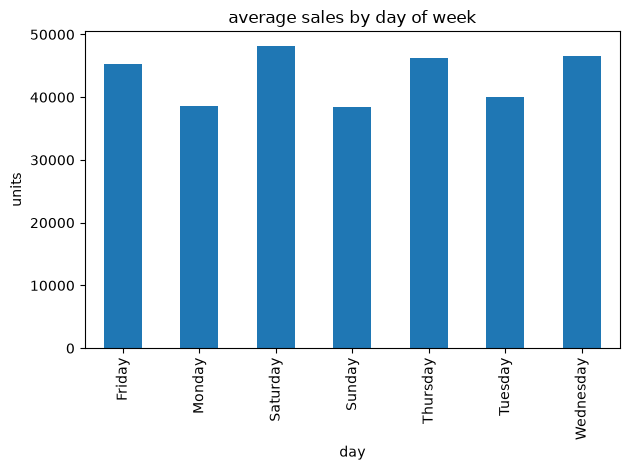

In [11]:
daily_sales["day"] = daily_sales["date"].dt.day_name()
daily_sales.groupby("day")["units"].mean().plot(kind="bar")
plt.title("average sales by day of week")
plt.ylabel("units")
plt.tight_layout()
plt.show()


### summary

we have 734 continuous days of data. we'll use product_group_name and focus on the top 6 categories: garment upper body, garment lower body, garment full body, swimwear, underwear, and accessories.
